In [ ]:
# Where the dataset and the outputs live.
#
# The dataset is looked for in this order:
#   1. the DATA_FILE environment variable, if it is set
#   2. data/uae_solar_dust_hourly_2015_20260731.csv in the repository
#   3. the same file inside data/uae_solar_dust_hourly_2015_20260731.zip, unzipped once
#   4. Google Drive, when the notebook runs in Colab and the file is kept there
# data/README.md explains how to obtain the file.

import os
import zipfile

DATA_NAME = 'uae_solar_dust_hourly_2015_20260731.csv'
REPO = os.getcwd()
if os.path.basename(REPO) == 'notebooks':
    REPO = os.path.dirname(REPO)


def find_dataset():
    if os.environ.get('DATA_FILE'):
        return os.environ['DATA_FILE']
    local = os.path.join(REPO, 'data', DATA_NAME)
    if os.path.exists(local):
        return local
    archive = local.replace('.csv', '.zip')
    if os.path.exists(archive):
        with zipfile.ZipFile(archive) as zipped:
            zipped.extract(DATA_NAME, os.path.join(REPO, 'data'))
        return local
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError(f'{DATA_NAME} not found. See data/README.md.')
    drive.mount('/content/drive')
    return '/content/drive/MyDrive/MSc_AI_Project/01_dataset/data/' + DATA_NAME


DATA_FILE = find_dataset()
OUT = os.environ.get('OUTPUT_DIR', os.path.join(REPO, 'outputs'))
FIGS = os.path.join(OUT, 'figures')
MODELS = os.path.join(OUT, 'models')
print('dataset:', DATA_FILE)
print('outputs:', OUT)


In [3]:
import os
import json
import time
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import tensorflow as tf

for folder in [OUT, FIGS, MODELS]:
    os.makedirs(folder, exist_ok=True)

print('NumPy', np.__version__, '| pandas', pd.__version__, '| Keras', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

NumPy 2.1.3 | pandas 2.2.3 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
plt.rcParams.update({
    'figure.figsize': (11, 4), 'figure.dpi': 100, 'font.size': 10,
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.6, 'legend.frameon': False,
})

CITIES = ['Abu Dhabi', 'Dubai', 'Al Ain']
CITY_COLOURS = {'Abu Dhabi': '#2a78d6', 'Dubai': '#eb6834', 'Al Ain': '#1baf7a'}


def save_figure(fig, name):
    fig.savefig(f'{FIGS}/{name}.png', dpi=150, bbox_inches='tight')

In [5]:
with open(DATA_FILE, 'rb') as f:
    fingerprint = hashlib.sha256(f.read()).hexdigest()
assert fingerprint.startswith('154dcf9d01384bc3'), 'this is not the checked dataset file'

df = pd.read_csv(DATA_FILE)
df['time'] = pd.to_datetime(df['timestamp_utc'])
df['city_id'] = df['site'].map({city: i for i, city in enumerate(CITIES)})
df = df.sort_values(['city_id', 'time']).reset_index(drop=True)

print('Rows and columns:', df.shape)
print('Period:', df['time'].min(), 'to', df['time'].max())
df[['site', 'time', 'ghi_wm2', 'aod_550nm', 'temp_2m_c', 'cloud_amount_pct']].head()

Rows and columns: (304560, 28)
Period: 2015-01-01 00:00:00 to 2026-07-31 23:00:00


,site,time,ghi_wm2,aod_550nm,temp_2m_c,cloud_amount_pct
0,Abu Dhabi,2015-01-01 00:00:00,0.00,0.23,20.20,54.46
1,Abu Dhabi,2015-01-01 01:00:00,0.00,0.23,20.09,55.28
2,Abu Dhabi,2015-01-01 02:00:00,0.00,0.22,19.81,40.42
3,Abu Dhabi,2015-01-01 03:00:00,32.12,0.22,19.62,32.63
4,Abu Dhabi,2015-01-01 04:00:00,213.30,0.22,20.50,20.81


In [6]:
for city, group in df.groupby('site', sort=False):
    steps = group['time'].diff().dropna()
    gaps = (steps != pd.Timedelta(hours=1)).sum()
    print(f'{city:10s} {len(group):7d} hours, {gaps} gaps or duplicated hours')

missing = df.isna().sum()
print('\nMissing values:', missing[missing > 0].to_dict())

night = df['solar_zenith_deg'] >= 90
print('Negative GHI values:', (df['ghi_wm2'] < 0).sum())
print('Largest GHI at night:', df.loc[night, 'ghi_wm2'].max(), 'W/m2')

Abu Dhabi   101520 hours, 0 gaps or duplicated hours
Dubai       101520 hours, 0 gaps or duplicated hours
Al Ain      101520 hours, 0 gaps or duplicated hours

Missing values: {'clearness_index_kt': 146650}
Negative GHI values: 0
Largest GHI at night: 0.0 W/m2


In [7]:
main_columns = ['ghi_wm2', 'clearsky_ghi_wm2', 'aod_550nm', 'temp_2m_c', 'rel_humidity_2m_pct', 'cloud_amount_pct']
df[main_columns].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ghi_wm2,304560.0,240.00,317.48,0.00,0.00,8.95,497.10,1090.00
clearsky_ghi_wm2,304560.0,256.79,333.48,0.00,0.00,9.73,549.80,1091.00
aod_550nm,304560.0,0.45,0.26,0.00,0.27,0.41,0.58,6.39
temp_2m_c,304560.0,28.81,7.13,7.41,23.19,29.00,33.85,49.52
rel_humidity_2m_pct,304560.0,52.59,21.03,3.34,37.94,54.21,68.48,100.00
cloud_amount_pct,304560.0,38.35,29.84,0.00,13.84,31.86,56.23,100.00


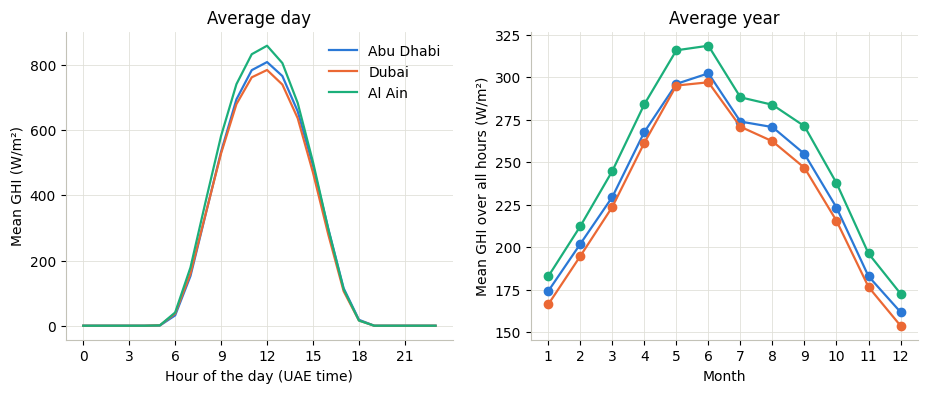

In [8]:
df['hour_uae'] = (df['time'].dt.hour + 4) % 24

fig, (ax1, ax2) = plt.subplots(1, 2)
for city in CITIES:
    city_df = df[df['site'] == city]
    colour = CITY_COLOURS[city]
    ax1.plot(city_df.groupby('hour_uae')['ghi_wm2'].mean(), color=colour, label=city)
    ax2.plot(city_df.groupby('month')['ghi_wm2'].mean(), color=colour, marker='o', label=city)

ax1.set(title='Average day', xlabel='Hour of the day (UAE time)', ylabel='Mean GHI (W/m²)', xticks=range(0, 24, 3))
ax2.set(title='Average year', xlabel='Month', ylabel='Mean GHI over all hours (W/m²)', xticks=range(1, 13))
ax1.legend()
save_figure(fig, 'fig01_daily_and_seasonal_cycle')
plt.show()

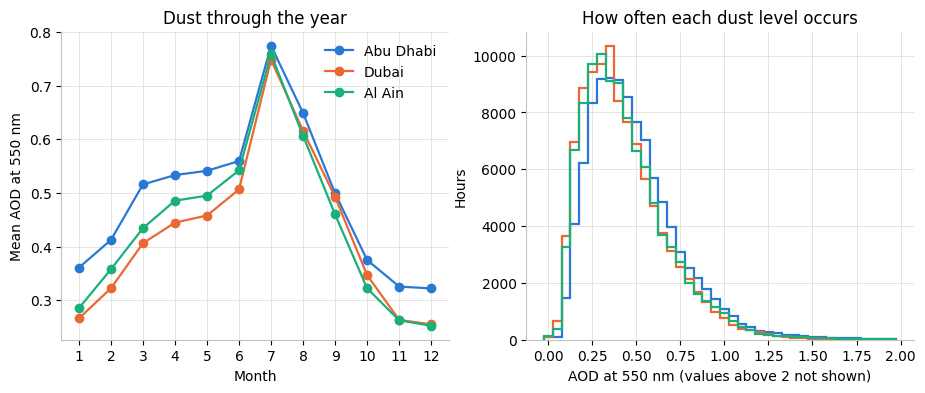

Share of hours with AOD above 1: 3.2 %


In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2)
bins = np.arange(-0.025, 2.0, 0.05)              # AOD has 2 decimals: each bin holds 5 values
for city in CITIES:
    city_df = df[df['site'] == city]
    colour = CITY_COLOURS[city]
    ax1.plot(city_df.groupby('month')['aod_550nm'].mean(), color=colour, marker='o', label=city)
    ax2.hist(city_df['aod_550nm'], bins=bins, histtype='step', linewidth=1.6, color=colour, label=city)

ax1.set(title='Dust through the year', xlabel='Month', ylabel='Mean AOD at 550 nm', xticks=range(1, 13))
ax2.set(title='How often each dust level occurs', xlabel='AOD at 550 nm (values above 2 not shown)', ylabel='Hours')
ax1.legend()
save_figure(fig, 'fig02_dust_by_month_and_distribution')
plt.show()

print('Share of hours with AOD above 1:', round(100 * (df['aod_550nm'] > 1).mean(), 1), '%')

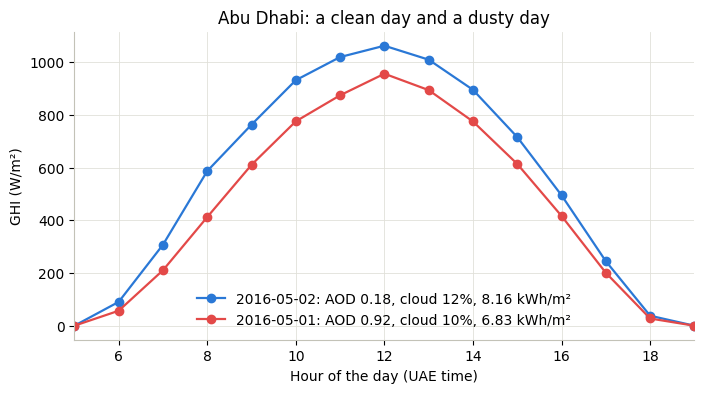

In [10]:
abu_dhabi = df[df['site'] == 'Abu Dhabi'].set_index('time')

fig, ax = plt.subplots(figsize=(8, 4))
for date, colour in [('2016-05-02', '#2a78d6'), ('2016-05-01', '#e34948')]:
    day = abu_dhabi.loc[date]
    energy = day['ghi_wm2'].sum() / 1000                       # hourly means add up to Wh/m2
    aod = day.loc[day['solar_zenith_deg'] < 85, 'aod_550nm'].mean()
    cloud = day.loc[day['solar_zenith_deg'] < 85, 'cloud_amount_pct'].mean()
    label = f'{date}: AOD {aod:.2f}, cloud {cloud:.0f}%, {energy:.2f} kWh/m²'
    ax.plot(day.index.hour + 4, day['ghi_wm2'], color=colour, marker='o', label=label)

ax.set(title='Abu Dhabi: a clean day and a dusty day', xlabel='Hour of the day (UAE time)',
       ylabel='GHI (W/m²)', xlim=(5, 19))
ax.legend()
save_figure(fig, 'fig03_clean_vs_dusty_day')
plt.show()

In [11]:
day_of_year = df['time'].dt.dayofyear
cos_zenith = np.cos(np.radians(df['solar_zenith_deg'].clip(upper=90)))
df['toa'] = 1361 * (1 + 0.033 * np.cos(2 * np.pi * day_of_year / 365)) * cos_zenith
daylight = (df['solar_zenith_deg'] < 85).to_numpy()

df['clearness'] = 0.0
df.loc[daylight, 'clearness'] = (df['ghi_wm2'] / df['toa'])[daylight].clip(0, 1)

lit = (df['ghi_wm2'] > 1).to_numpy()
df['diffuse_fraction'] = 0.0
df.loc[lit, 'diffuse_fraction'] = (df['dhi_wm2'] / df['ghi_wm2'])[lit].clip(0, 1)

print('Daylight hours:', daylight.sum(), 'of', len(df))

Daylight hours: 143545 of 304560


In [12]:
features = pd.DataFrame(index=df.index)

# sunlight (6)
features['ghi'] = df['ghi_wm2']
features['dni'] = df['dni_wm2']
features['dhi'] = df['dhi_wm2']
features['clearness'] = df['clearness']
features['diffuse_fraction'] = df['diffuse_fraction']
features['clearsky_ghi'] = df['clearsky_ghi_wm2']

# sun position and season (5)
hour = df['time'].dt.hour
features['cos_zenith'] = cos_zenith
features['hour_sin'] = np.sin(2 * np.pi * hour / 24)
features['hour_cos'] = np.cos(2 * np.pi * hour / 24)
features['day_sin'] = np.sin(2 * np.pi * day_of_year / 365)
features['day_cos'] = np.cos(2 * np.pi * day_of_year / 365)

In [13]:
# dust (4): these four are left out in the "without AOD" experiment
features['aod_550'] = df['aod_550nm']
features['aod_840'] = df['aod_840nm']
features['angstrom'] = (-np.log(df['aod_550nm'].clip(lower=0.01) / df['aod_840nm'].clip(lower=0.01))
                        / np.log(550 / 840))          # a low value means coarse dust particles
features['aod_change'] = df.groupby('city_id')['aod_550nm'].diff().fillna(0)

# weather (10)
weather_columns = {'temp': 'temp_2m_c', 'dewpoint': 'dewpoint_2m_c', 'rel_humidity': 'rel_humidity_2m_pct',
                   'specific_humidity': 'specific_humidity_2m_gkg', 'wind_speed': 'wind_speed_10m_ms',
                   'pressure': 'surface_pressure_kpa', 'rain': 'precip_mmhr', 'cloud_amount': 'cloud_amount_pct'}
for name, column in weather_columns.items():
    features[name] = df[column]
wind_direction = np.radians(df['wind_dir_10m_deg'])
features['wind_u'] = df['wind_speed_10m_ms'] * np.sin(wind_direction)
features['wind_v'] = df['wind_speed_10m_ms'] * np.cos(wind_direction)

# city, one-hot (3)
for i, name in enumerate(['is_abu_dhabi', 'is_dubai', 'is_al_ain']):
    features[name] = (df['city_id'] == i).astype(float)

In [14]:
AOD_FEATURES = ['aod_550', 'aod_840', 'angstrom', 'aod_change']
FEATURES_ALL = list(features.columns)
FEATURES_NO_AOD = [name for name in FEATURES_ALL if name not in AOD_FEATURES]
features = features.astype('float32')

print(len(FEATURES_ALL), 'inputs with AOD,', len(FEATURES_NO_AOD), 'without AOD')
print('Missing or infinite values:', (~np.isfinite(features.to_numpy())).sum())
features.astype('float64').describe().T[['mean', 'std', 'min', 'max']].round(3)

28 inputs with AOD, 24 without AOD
Missing or infinite values: 0


,mean,std,min,max
ghi,240.000,317.478,0.000,1090.000
dni,186.801,255.352,0.000,1214.000
dhi,104.089,130.255,0.000,616.300
clearness,0.276,0.308,0.000,0.831
diffuse_fraction,0.291,0.327,0.000,1.000
clearsky_ghi,256.789,333.479,0.000,1091.000
cos_zenith,0.282,0.344,0.000,0.997
hour_sin,0.000,0.707,-1.000,1.000
hour_cos,-0.000,0.707,-1.000,1.000
day_sin,0.026,0.704,-1.000,1.000


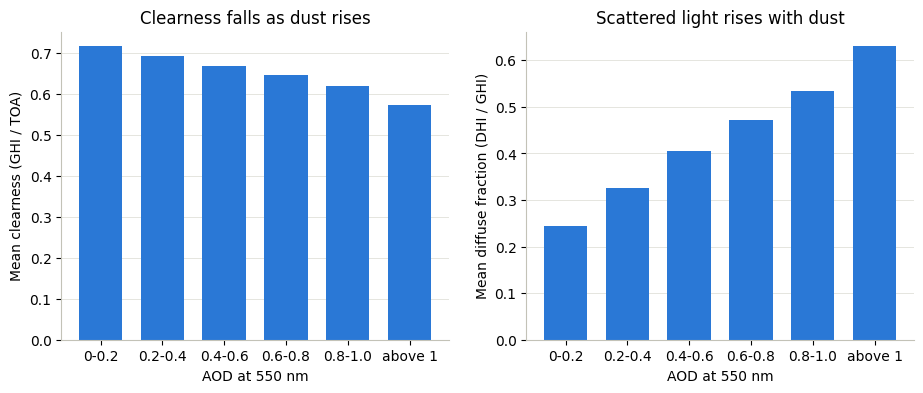

Cloud-free daylight hours: 25269


,clearness,diffuse_fraction,hours
aod_550nm,,,
0-0.2,0.715,0.245,4218
0.2-0.4,0.691,0.327,10366
0.4-0.6,0.668,0.406,6801
0.6-0.8,0.645,0.473,2510
0.8-1.0,0.620,0.534,879
above 1,0.572,0.630,495


In [15]:
cloud_free = df[daylight & (df['cloud_amount_pct'] < 5).to_numpy()]
aod_level = pd.cut(cloud_free['aod_550nm'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0, 7],
                   labels=['0-0.2', '0.2-0.4', '0.4-0.6', '0.6-0.8', '0.8-1.0', 'above 1'], include_lowest=True)
by_level = cloud_free.groupby(aod_level, observed=True)[['clearness', 'diffuse_fraction']].mean()
by_level['hours'] = aod_level.value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.bar(by_level.index, by_level['clearness'], color='#2a78d6', width=0.7)
ax2.bar(by_level.index, by_level['diffuse_fraction'], color='#2a78d6', width=0.7)
ax1.set(title='Clearness falls as dust rises', xlabel='AOD at 550 nm', ylabel='Mean clearness (GHI / TOA)')
ax2.set(title='Scattered light rises with dust', xlabel='AOD at 550 nm', ylabel='Mean diffuse fraction (DHI / GHI)')
for ax in (ax1, ax2):
    ax.set_axisbelow(True)
    ax.grid(axis='x', visible=False)
save_figure(fig, 'fig04_dust_physics_check')
plt.show()

print('Cloud-free daylight hours:', len(cloud_free))
by_level.round(3)

In [16]:
H = np.array([1, 6, 24])          # forecast horizons in hours
HORIZONS = ['t+1', 't+6', 't+24']
WINDOW = 24                       # hours of history in each sample
HOURS_PER_CITY = 101_520

X_hourly = features.to_numpy()
ghi = df['ghi_wm2'].to_numpy(np.float32)
toa = df['toa'].to_numpy(np.float32)
cos_z = features['cos_zenith'].to_numpy()
times = df['time'].to_numpy()
city = df['city_id'].to_numpy()

In [17]:
# a forecast time t needs 24 hours of history and a t+24 target inside the same city
origin = np.concatenate([np.arange(c * HOURS_PER_CITY + WINDOW - 1, (c + 1) * HOURS_PER_CITY - H.max())
                         for c in range(3)])
target = origin[:, None] + H[None, :]          # row numbers of t+1, t+6 and t+24

is_day = daylight[target]                      # which targets are in daylight
keep = is_day.any(axis=1)                      # drop forecast times whose three targets are all at night
origin, target, is_day = origin[keep], target[keep], is_day[keep]

print('Forecast times:', len(origin))
print('Daylight targets:', dict(zip(HORIZONS, is_day.sum(axis=0).tolist())))

Forecast times: 219598
Daylight targets: {'t+1': 143479, 't+6': 143488, 't+24': 143491}


In [18]:
window = origin[:, None] + np.arange(-WINDOW + 1, 1)[None, :]     # rows t-23 ... t
X = X_hourly[window]                                                # (samples, 24, 28)

toa_target = toa[target]
ghi_target = ghi[target]
F = np.concatenate([cos_z[target], toa_target], axis=1)            # sun position at the target hours
Y = np.where(is_day, ghi_target / np.where(toa_target > 0, toa_target, 1), 0).clip(0, 1).astype(np.float32)

# checks: the window ends at t, starts at t-23, and never crosses into another city
assert (times[window[:, -1]] == times[origin]).all()
assert (times[window[:, 0]] == times[origin] - np.timedelta64(23, 'h')).all()
assert (city[window[:, 0]] == city[origin]).all() and (city[target[:, -1]] == city[origin]).all()

print('Inputs X:', X.shape, '| known future inputs F:', F.shape, '| targets Y:', Y.shape)

Inputs X: (219598, 24, 28) | known future inputs F: (219598, 6) | targets Y: (219598, 3)


In [19]:
year = df['time'].dt.year.to_numpy()[origin]
split = np.where(year <= 2022, 'train', np.where(year == 2023, 'validation', 'test'))
TRAIN = np.flatnonzero(split == 'train')
VAL = np.flatnonzero(split == 'validation')
TEST = np.flatnonzero(split == 'test')
print('Samples - train:', len(TRAIN), '| validation:', len(VAL), '| test:', len(TEST))

# targets used for learning: daylight, and inside the sample's own set
target_time = times[target]
use_target = is_day.copy()
use_target[TRAIN] &= target_time[TRAIN] < np.datetime64('2023-01-01')
use_target[VAL] &= target_time[VAL] < np.datetime64('2024-01-01')
print('Boundary targets left out:', int((is_day & ~use_target).sum()))

Samples - train: 151551 | validation: 18939 | test: 49108
Boundary targets left out: 66


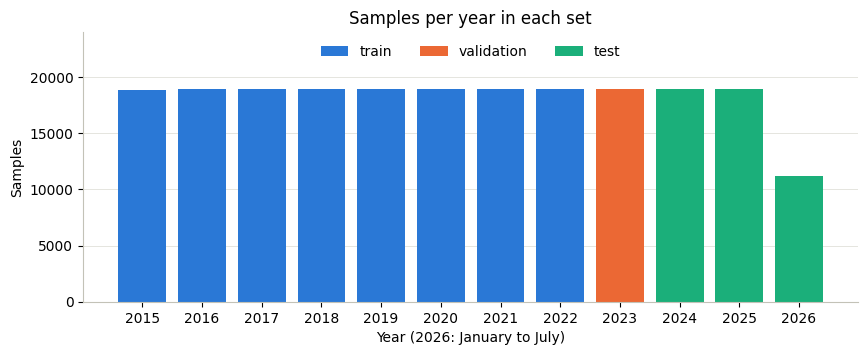

In [20]:
samples_per_year = pd.crosstab(year, split)[['train', 'validation', 'test']]
split_colours = {'train': '#2a78d6', 'validation': '#eb6834', 'test': '#1baf7a'}

fig, ax = plt.subplots(figsize=(10, 3.5))
for name in ['train', 'validation', 'test']:
    ax.bar(samples_per_year.index, samples_per_year[name], color=split_colours[name], width=0.8, label=name)
ax.set(title='Samples per year in each set', xlabel='Year (2026: January to July)', ylabel='Samples',
       xticks=samples_per_year.index, ylim=(0, 24000))
ax.set_axisbelow(True)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', ncol=3)
save_figure(fig, 'fig05_train_validation_test_split')
plt.show()

In [21]:
train_rows = X[TRAIN].reshape(-1, X.shape[2])
x_mean = train_rows.mean(axis=0, dtype=np.float64).astype(np.float32)
x_std = train_rows.std(axis=0, dtype=np.float64).astype(np.float32)
x_std[x_std < 1e-6] = 1                       # guard against a constant input
del train_rows
f_mean = F[TRAIN].mean(axis=0).astype(np.float32)
f_std = F[TRAIN].std(axis=0).astype(np.float32)

X_in = (X - x_mean) / x_std
F_in = (F - f_mean) / f_std

check = X_in[TRAIN].reshape(-1, X.shape[2])
print('Training inputs after scaling - largest |mean|:', round(float(np.abs(check.mean(axis=0, dtype=np.float64)).max()), 6),
      '| largest |std - 1|:', round(float(np.abs(check.std(axis=0, dtype=np.float64) - 1).max()), 6))
del check

Training inputs after scaling - largest |mean|: 2e-06 | largest |std - 1|: 0.0


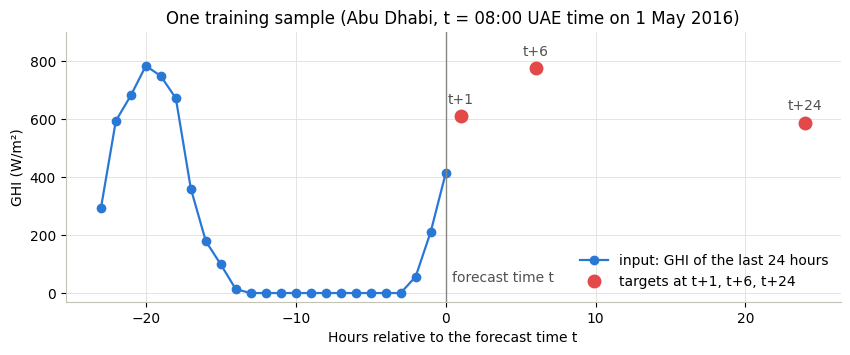

Input window shape: (24, 28) | known future inputs: (6,) | target clearness: [0.603 0.685 0.752]


In [22]:
# one training sample: Abu Dhabi, forecast made at 08:00 UAE time on the dusty day of 1 May 2016
sample = np.flatnonzero((times[origin] == np.datetime64('2016-05-01T04:00')) & (city[origin] == 0))[0]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(np.arange(-WINDOW + 1, 1), ghi[window[sample]], color='#2a78d6', marker='o', label='input: GHI of the last 24 hours')
ax.plot(H, ghi_target[sample], 'o', color='#e34948', markersize=9, label='targets at t+1, t+6, t+24')
for h, value, label in zip(H, ghi_target[sample], HORIZONS):
    ax.annotate(label, (h, value), textcoords='offset points', xytext=(0, 9), ha='center', color='#52514e')
ax.axvline(0, color='#898781', linewidth=1)
ax.text(0.4, 40, 'forecast time t', color='#52514e')
ax.set(title='One training sample (Abu Dhabi, t = 08:00 UAE time on 1 May 2016)',
       xlabel='Hours relative to the forecast time t', ylabel='GHI (W/m²)', ylim=(-30, 900))
ax.legend(loc='lower right')
save_figure(fig, 'fig06_one_training_sample')
plt.show()

print('Input window shape:', X_in[sample].shape, '| known future inputs:', F_in[sample].shape,
      '| target clearness:', Y[sample].round(3))

In [23]:
def rmse(observed, forecast):
    return float(np.sqrt(np.mean((forecast - observed) ** 2)))


def mae(observed, forecast):
    return float(np.mean(np.abs(forecast - observed)))


def evaluate(forecast, rows, mask):
    """RMSE and MAE (W/m2) for each horizon, on the given samples and daylight targets only."""
    result = {}
    for k, horizon in enumerate(HORIZONS):
        ok = mask[rows, k]
        observed, predicted = ghi_target[rows, k][ok], forecast[rows, k][ok]
        result[horizon] = {'RMSE': rmse(observed, predicted), 'MAE': mae(observed, predicted)}
    return pd.DataFrame(result).T

In [24]:
# same hour yesterday: GHI at t+h-24, which is inside the input window
pred_yesterday = np.where(is_day, ghi[target - 24], 0)

# climatology: average training clearness for each city, month and hour, times TOA at the target
month_t = df['month'].to_numpy()[target]
hour_t = df['time'].dt.hour.to_numpy()[target]
city_t = city[target]
learn = np.zeros_like(is_day)
learn[TRAIN] = use_target[TRAIN]
climate = pd.DataFrame({'city': city_t[learn], 'month': month_t[learn], 'hour': hour_t[learn], 'clearness': Y[learn]})
mean_clearness = climate.groupby(['city', 'month', 'hour'])['clearness'].mean()
lookup = pd.MultiIndex.from_arrays([city_t.ravel(), month_t.ravel(), hour_t.ravel()])
clim_clearness = mean_clearness.reindex(lookup).fillna(0).to_numpy().reshape(target.shape)
pred_climatology = np.where(is_day, clim_clearness * toa_target, 0)

In [25]:
clearsky = df['clearsky_ghi_wm2'].to_numpy(np.float64)
doy = day_of_year.to_numpy()
hour_all = df['time'].dt.hour.to_numpy()

# reference A: average clear-sky GHI of the training years for each city, day of year (+-7 days) and hour
past = df['time'].dt.year.to_numpy() <= 2022
total, count = np.zeros((3, 366, 24)), np.zeros((3, 366, 24))
np.add.at(total, (city[past], doy[past] - 1, hour_all[past]), clearsky[past])
np.add.at(count, (city[past], doy[past] - 1, hour_all[past]), 1)


def two_week_sum(a):
    return sum(np.roll(a, shift, axis=1) for shift in range(-7, 8))


clearsky_avg = (two_week_sum(total) / two_week_sum(count))[city, doy - 1, hour_all]

In [26]:
def latest_clear_sky_index(reference):
    """GHI / clear-sky reference at the latest daylight hour up to each forecast time (past data only)."""
    ok = daylight & (reference > 10)
    index = pd.Series(np.where(ok, ghi / np.where(ok, reference, 1), np.nan)).clip(0, 1.5)
    return index.groupby(city).ffill().fillna(0).to_numpy()[origin]


pred_smart_a = np.where(is_day, latest_clear_sky_index(clearsky_avg)[:, None] * clearsky_avg[target], 0)
pred_smart_b = np.where(is_day, latest_clear_sky_index(clearsky)[:, None] * clearsky[target - 24], 0)

In [27]:
BASELINES = {'Same hour yesterday': pred_yesterday, 'Climatology': pred_climatology,
             'Smart persistence A': pred_smart_a, 'Smart persistence B': pred_smart_b}

val_rmse = pd.DataFrame({name: evaluate(pred, VAL, use_target)['RMSE'] for name, pred in BASELINES.items()}).T
test_rmse = pd.DataFrame({name: evaluate(pred, TEST, is_day)['RMSE'] for name, pred in BASELINES.items()}).T

BEST_BASELINE = val_rmse.idxmin()            # chosen on the validation year, one per horizon
print('Validation RMSE (W/m2):')
print(val_rmse.round(1))
print('\nTest RMSE (W/m2):')
print(test_rmse.round(1))
print('\nBest baseline per horizon (chosen on validation):', BEST_BASELINE.to_dict())

Validation RMSE (W/m2):
                      t+1   t+6  t+24
Same hour yesterday  72.6  72.6  72.4
Climatology          66.9  66.9  66.9
Smart persistence A  27.7  75.0  72.4
Smart persistence B  35.2  65.7  72.4

Test RMSE (W/m2):
                      t+1   t+6  t+24
Same hour yesterday  85.6  85.6  85.6
Climatology          81.5  81.5  81.5
Smart persistence A  30.1  82.0  85.7
Smart persistence B  38.9  72.9  85.6

Best baseline per horizon (chosen on validation): {'t+1': 'Smart persistence A', 't+6': 'Smart persistence B', 't+24': 'Climatology'}


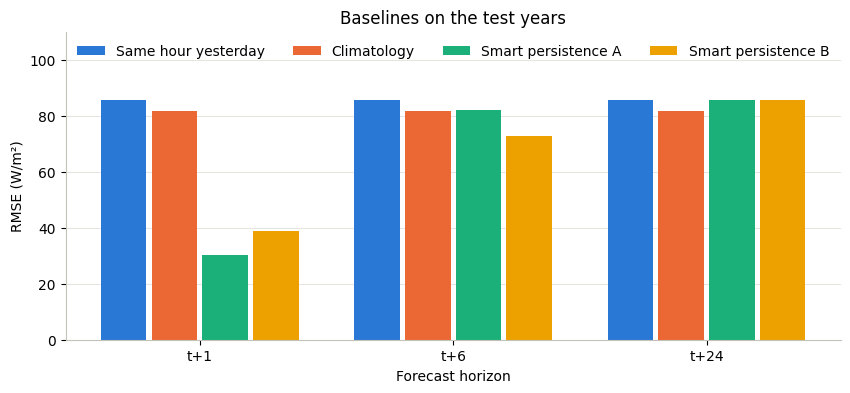

In [28]:
baseline_colours = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
x = np.arange(len(HORIZONS))
width = 0.2

fig, ax = plt.subplots(figsize=(10, 4))
for i, name in enumerate(BASELINES):
    ax.bar(x + (i - 1.5) * width, test_rmse.loc[name], width=width * 0.9, color=baseline_colours[i], label=name)
ax.set(title='Baselines on the test years', xticks=x, xticklabels=HORIZONS, xlabel='Forecast horizon',
       ylabel='RMSE (W/m²)', ylim=(0, 110))
ax.set_axisbelow(True)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', ncol=4)
save_figure(fig, 'fig07_baselines_test_rmse')
plt.show()

In [29]:
# activation functions and their slopes, written with the neuron's own output O
def sigmoid(net):
    return 1 / (1 + np.exp(-net))

def sigmoid_slope(O):
    return O * (1 - O)

def tanh_slope(O):
    return 1 - O ** 2
def linear(net):
    return net
def linear_slope(O):
    return np.ones_like(O)


ACTIVATIONS = {'sigmoid': (sigmoid, sigmoid_slope), 'tanh': (np.tanh, tanh_slope), 'linear': (linear, linear_slope)}


In [30]:
def forward(x, net):
    f_hidden = ACTIVATIONS[net['hidden']][0]
    f_out = ACTIVATIONS[net['output']][0]
    net_k = x @ net['W1'] + net['b1']          # equation (1)
    O_k = f_hidden(net_k)                      # equation (2)
    net_o = O_k @ net['W2'] + net['b2']        # equation (3)
    O_o = f_out(net_o)                         # equation (4)
    return O_k, O_o

In [31]:
def error(t, O_o, m):
    return 0.5 * np.sum(m * (t - O_o) ** 2) / len(t)       # equation (5), mean over the patterns

In [32]:
def backward(t, m, O_k, O_o, net):
    slope_hidden = ACTIVATIONS[net['hidden']][1]
    slope_out = ACTIVATIONS[net['output']][1]
    delta_o = m * (t - O_o) * slope_out(O_o)                   # equation (6): output delta
    delta_k = slope_hidden(O_k) * (delta_o @ net['W2'].T)       # equation (7): hidden delta, sent backwards
    return delta_o, delta_k

In [33]:
def update(x, O_k, delta_o, delta_k, net, step, eta, alpha=0.0, lam=0.0):
    n = len(x)
    delta_x = {'W2': O_k.T @ delta_o / n, 'b2': delta_o.mean(axis=0),      # delta x input, equation (8)
               'W1': x.T @ delta_k / n, 'b1': delta_k.mean(axis=0)}
    for name, change in delta_x.items():
        if name.startswith('W'):
            change = change - lam * net[name]                              # L2 weight decay
        step[name] = eta * change + alpha * step[name]                     # momentum, equation (9)
        net[name] += step[name]


In [ ]:
# Correctness check, not included in this public copy.
#
# Before training on real data, forward(), error(), backward() and update() were run on a small
# 2-2-1 sigmoid network and reproduced an independent hand calculation to four decimal places over
# two epochs, with and without L2 weight decay. That check is built on teaching material from the
# module, so it is left out here. It trains nothing and changes none of the results below.


In [37]:
def new_network(n_inputs, n_hidden, n_outputs, rng):
    """Small random weights, scaled so that the tanh neurons start in their middle region."""
    return {'W1': rng.normal(0, 1 / np.sqrt(n_inputs), (n_inputs, n_hidden)).astype(np.float32),
            'b1': np.zeros(n_hidden, np.float32),
            'W2': rng.normal(0, 1 / np.sqrt(n_hidden), (n_hidden, n_outputs)).astype(np.float32),
            'b2': np.zeros(n_outputs, np.float32), 'hidden': 'tanh', 'output': 'linear'}


def make_inputs(rows, columns):
    """Flatten the 24-hour window of the chosen features and add the 6 known future values."""
    window_part = X_in[rows][:, :, columns].reshape(len(rows), -1)
    return np.concatenate([window_part, F_in[rows]], axis=1)


def daylight_mse(net, x, t, m):
    """Mean squared clearness error over the daylight targets (used for the learning curves)."""
    O_o = forward(x, net)[1]
    return float(np.sum(m * (t - O_o) ** 2) / m.sum())


def to_ghi(clearness, rows):
    """GHI forecast (W/m2) = predicted clearness x TOA at the target hours, 0 at night."""
    forecast = np.zeros_like(ghi_target)
    forecast[rows] = np.where(is_day[rows], np.clip(clearness, 0, None) * toa_target[rows], 0)
    return forecast


In [38]:
def train_m0(columns, seed, n_hidden=64, eta=0.01, alpha=0.9, lam=1e-4, batch=256, max_epochs=60, patience=5):
    rng = np.random.default_rng(seed)
    x_train, x_val = make_inputs(TRAIN, columns), make_inputs(VAL, columns)
    t_train, m_train = Y[TRAIN], use_target[TRAIN].astype(np.float32)
    t_val, m_val = Y[VAL], use_target[VAL].astype(np.float32)
    net = new_network(x_train.shape[1], n_hidden, 3, rng)
    step = {name: np.zeros_like(net[name]) for name in ['W1', 'b1', 'W2', 'b2']}
    best_error, best_net, wait, history = np.inf, None, 0, []

    for epoch in range(1, max_epochs + 1):
        order = rng.permutation(len(x_train))
        for start in range(0, len(order), batch):
            b = order[start:start + batch]
            O_k, O_o = forward(x_train[b], net)                                   # step 1: forward pass
            delta_o, delta_k = backward(t_train[b], m_train[b], O_k, O_o, net)    # step 3: backpropagation
            update(x_train[b], O_k, delta_o, delta_k, net, step, eta, alpha, lam)  # step 4: weight update
        train_error = daylight_mse(net, x_train, t_train, m_train)               # step 2: error, after each epoch
        val_error = daylight_mse(net, x_val, t_val, m_val)
        history.append((epoch, train_error, val_error))

        if val_error < best_error:                                                # early stopping with patience
            best_error, wait = val_error, 0
            best_net = {name: value.copy() if isinstance(value, np.ndarray) else value    # checkpoint of the best weights
                        for name, value in net.items()}
        else:
            wait += 1
            if wait >= patience:
                break
    return best_net, pd.DataFrame(history, columns=['epoch', 'train', 'validation'])


In [39]:
ALL_COLUMNS = list(range(len(FEATURES_ALL)))
tuning_file = f'{OUT}/m0_learning_rate_search.csv'

if os.path.exists(tuning_file):
    tuning = pd.read_csv(tuning_file)
    print('Loaded the earlier search from Drive.')
else:
    rows = []
    for eta in [0.01, 0.03, 0.05, 0.1]:
        start = time.time()
        _, history = train_m0(ALL_COLUMNS, seed=0, eta=eta)
        for _, r in history.iterrows():
            rows.append({'eta': eta, 'epoch': int(r.epoch), 'train': r.train, 'validation': r.validation})
        print(f'eta = {eta}: {len(history)} epochs, best validation error {history.validation.min():.5f}, '
              f'{time.time() - start:.0f} s')
    tuning = pd.DataFrame(rows)
    tuning.to_csv(tuning_file, index=False)

best_per_eta = tuning.groupby('eta')['validation'].min()
ETA = float(best_per_eta.idxmin())
print('\nBest validation error for each learning rate:')
print(best_per_eta.round(5))
print('\nChosen learning rate:', ETA)

Loaded the earlier search from Drive.

Best validation error for each learning rate:
eta
0.01    0.00276
0.03    0.00275
0.05    0.00272
0.10    0.00295
Name: validation, dtype: float64

Chosen learning rate: 0.05


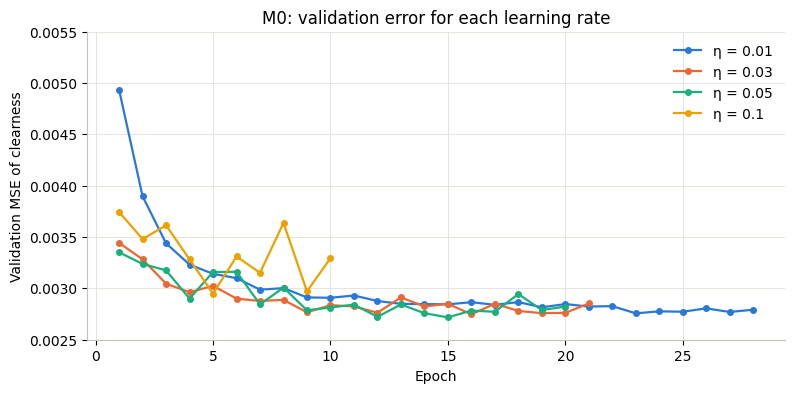

In [40]:
eta_colours = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']

fig, ax = plt.subplots(figsize=(9, 4))
for colour, (eta, curve) in zip(eta_colours, tuning.groupby('eta')):
    ax.plot(curve['epoch'], curve['validation'], color=colour, marker='o', markersize=4, label=f'η = {eta}')
ax.set(title='M0: validation error for each learning rate', xlabel='Epoch',
       ylabel='Validation MSE of clearness', ylim=(0.0025, 0.0055))
ax.legend()
save_figure(fig, 'fig08_m0_learning_rate_search')
plt.show()

In [41]:
SEEDS = [0, 1, 2]
INPUT_SETS = {'with AOD': ALL_COLUMNS, 'without AOD': [FEATURES_ALL.index(name) for name in FEATURES_NO_AOD]}
m0_runs = {}

for set_name, columns in INPUT_SETS.items():
    for seed in SEEDS:
        path = f"{MODELS}/M0_{set_name.replace(' ', '_')}_seed{seed}.npz"
        if os.path.exists(path):
            saved = np.load(path)
            history = pd.DataFrame(saved['history'], columns=['epoch', 'train', 'validation'])
            test_clearness = saved['test_clearness']
            print(f'M0 {set_name:11s} seed {seed}: loaded from Drive')
        else:
            start = time.time()
            net, history = train_m0(columns, seed, eta=ETA)
            test_clearness = forward(make_inputs(TEST, columns), net)[1]
            np.savez(path, W1=net['W1'], b1=net['b1'], W2=net['W2'], b2=net['b2'],
                     history=history.to_numpy(), test_clearness=test_clearness)
            print(f'M0 {set_name:11s} seed {seed}: {len(history)} epochs, {time.time() - start:.0f} s')
        m0_runs[(set_name, seed)] = {'history': history, 'forecast': to_ghi(test_clearness, TEST)}

print('M0 networks ready:', len(m0_runs))

M0 with AOD    seed 0: loaded from Drive
M0 with AOD    seed 1: loaded from Drive
M0 with AOD    seed 2: loaded from Drive
M0 without AOD seed 0: loaded from Drive
M0 without AOD seed 1: loaded from Drive
M0 without AOD seed 2: loaded from Drive
M0 networks ready: 6


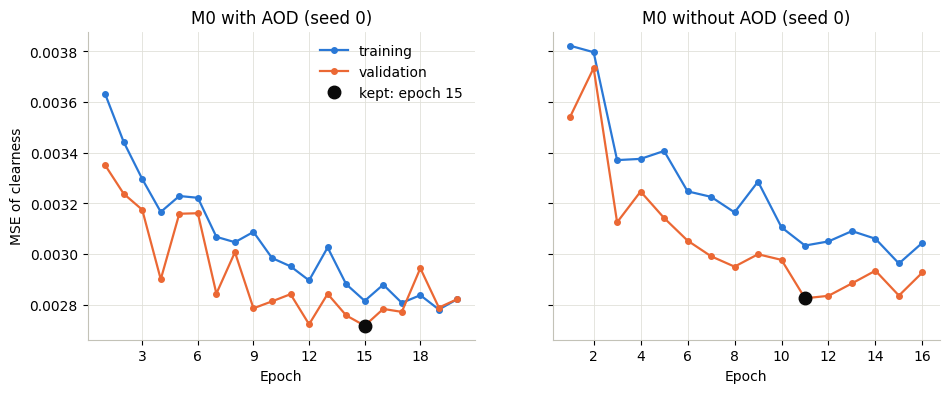

In [42]:
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, set_name in zip(axes, INPUT_SETS):
    history = m0_runs[(set_name, 0)]['history']
    best = history.loc[history['validation'].idxmin()]
    ax.plot(history['epoch'], history['train'], color='#2a78d6', marker='o', markersize=4, label='training')
    ax.plot(history['epoch'], history['validation'], color='#eb6834', marker='o', markersize=4, label='validation')
    ax.plot(best['epoch'], best['validation'], 'o', color='#0b0b0b', markersize=9, label=f"kept: epoch {int(best['epoch'])}")
    ax.set(title=f'M0 {set_name} (seed 0)', xlabel='Epoch')
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel('MSE of clearness')
axes[0].legend()
save_figure(fig, 'fig09_m0_learning_curves')
plt.show()

In [43]:
best_baseline_rmse = pd.Series({h: test_rmse.loc[BEST_BASELINE[h], h] for h in HORIZONS})

m0_scores = []
for (set_name, seed), run in m0_runs.items():
    scores = evaluate(run['forecast'], TEST, is_day)
    for h in HORIZONS:
        m0_scores.append({'inputs': set_name, 'seed': seed, 'horizon': h, 'RMSE': scores.loc[h, 'RMSE'], 'MAE': scores.loc[h, 'MAE']})
m0_scores = pd.DataFrame(m0_scores)

m0_table = m0_scores.groupby(['inputs', 'horizon'], sort=False)[['RMSE', 'MAE']].agg(['mean', 'std'])
m0_table[('vs best baseline', '%')] = [100 * (1 - m0_table.loc[(s, h), ('RMSE', 'mean')] / best_baseline_rmse[h])
                                       for s, h in m0_table.index]
print('Best baseline RMSE on the test years:', best_baseline_rmse.round(1).to_dict())
print('M0 on the test years (mean and standard deviation over 3 random restarts; positive % = better than the baseline):')
m0_table.round(1)

Best baseline RMSE on the test years: {'t+1': 30.1, 't+6': 72.9, 't+24': 81.5}
M0 on the test years (mean and standard deviation over 3 random restarts; positive % = better than the baseline):


RMSE        MAE      vs best baseline
                     mean  std  mean  std                %
inputs      horizon                                       
with AOD    t+1      31.6  0.9  18.0  0.5             -5.1
            t+6      55.0  0.4  29.6  0.3             24.5
            t+24     73.2  1.1  40.2  1.2             10.2
without AOD t+1      33.1  0.7  19.5  0.5             -9.9
            t+6      58.3  0.5  32.3  0.1             20.0
            t+24     72.9  0.5  39.4  0.3             10.6

In [44]:
# the training error lies above the validation error in fig09: is 2023 simply an easier year? The baseline answers it
pd.concat({'training years': evaluate(pred_climatology, TRAIN, use_target)['RMSE'],
           'validation year': evaluate(pred_climatology, VAL, use_target)['RMSE']}, axis=1).round(1)

,training years,validation year
t+1,72.0,66.9
t+6,72.0,66.9
t+24,72.0,66.9


In [45]:
def keras_data(rows, columns):
    """Inputs, targets and daylight weights as Keras expects them: two inputs, three outputs."""
    inputs = [X_in[rows][:, :, columns], F_in[rows]]
    targets = [Y[rows, k] for k in range(len(H))]
    weights = [use_target[rows, k].astype(np.float32) for k in range(len(H))]
    return inputs, targets, weights

In [46]:
from keras import layers

KERAS_MODELS = {'M1 MLP': 'MLP', 'M2 SimpleRNN': 'SimpleRNN', 'M3 LSTM': 'LSTM', 'M4 GRU': 'GRU', 'M5 CNN': 'CNN'}
RECURRENT = {'SimpleRNN': layers.SimpleRNN, 'LSTM': layers.LSTM, 'GRU': layers.GRU}


def build_model(kind, n_features):
    window = keras.Input(shape=(WINDOW, n_features), name='window')
    future = keras.Input(shape=(F.shape[1],), name='future')
    if kind == 'MLP':
        h = layers.Flatten()(window)
    elif kind == 'CNN':
        h = layers.Conv1D(32, 3, padding='same', activation='relu')(window)     # 32 filters, each 3 hours wide
        h = layers.MaxPooling1D(2)(h)
        h = layers.Flatten()(h)
    else:
        h = RECURRENT[kind](64)(window)                                          # many-to-one: last hidden state
    h = layers.Concatenate()([h, future])
    h = layers.Dense(64, activation='tanh')(h)
    h = layers.Dropout(0.2)(h)
    outputs = [layers.Dense(1, name=f'ahead_{k}h')(h) for k in H]                # one linear output per horizon
    return keras.Model([window, future], outputs, name=kind)

In [47]:
lstm = build_model('LSTM', len(FEATURES_ALL))
lstm.summary()

u, d = 64, len(FEATURES_ALL)
print('LSTM parameter count, 4(ud + u^2 + u) =', 4 * (u * d + u ** 2 + u))


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ window (InputLayer) │ (None, 24, 28)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     23,808 │ window[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future (InputLayer) │ (None, 6)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 70)        │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ future[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      4,544 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ahead_1h (Dense)    │ (None, 1)         │         65 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ahead_6h (Dense)    │ (None, 1)         │         65 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ahead_24h (Dense)   │ (None, 1)         │         65 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 28,547 (111.51 KB)

 Trainable params: 28,547 (111.51 KB)

 Non-trainable params: 0 (0.00 B)

LSTM parameter count, 4(ud + u^2 + u) = 23808


In [48]:
m0_inputs = WINDOW * len(FEATURES_ALL) + F.shape[1]
n_params = {'M0 NumPy': m0_inputs * 64 + 64 + 64 * 3 + 3}
for label, kind in KERAS_MODELS.items():
    n_params[label] = build_model(kind, len(FEATURES_ALL)).count_params()

print('Weights and biases of each network (with the 28 inputs):')
pd.Series(n_params, name='parameters')

Weights and biases of each network (with the 28 inputs):


,parameters
M0 NumPy,43651
M1 MLP,43651
M2 SimpleRNN,10691
M3 LSTM,28547
M4 GRU,22787
M5 CNN,27939


In [49]:
def fit_keras(kind, columns, seed):
    keras.utils.set_random_seed(seed)                                    # random restart number `seed`
    model = build_model(kind, len(columns))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001, clipnorm=1.0), loss='mse')
    x_train, t_train, m_train = keras_data(TRAIN, columns)
    x_val, t_val, m_val = keras_data(VAL, columns)
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    fit = model.fit(x_train, t_train, sample_weight=m_train, validation_data=(x_val, t_val, m_val),
                    epochs=60, batch_size=256, callbacks=[stop], verbose=0)     # forward, backpropagation, update
    epochs = np.arange(1, len(fit.history['loss']) + 1)
    return model, np.column_stack([epochs, fit.history['loss'], fit.history['val_loss']])


def forecast_clearness(model, rows, columns):
    return np.hstack(model.predict(keras_data(rows, columns)[0], batch_size=4096, verbose=0))

In [50]:
keras_runs = {}


def train_all(label):
    """Train (or load from Drive) one network type: with and without AOD, 3 random restarts each."""
    for set_name, columns in INPUT_SETS.items():
        for seed in SEEDS:
            path = f"{MODELS}/{label.replace(' ', '_')}_{set_name.replace(' ', '_')}_seed{seed}"
            if os.path.exists(path + '.npz'):
                saved = np.load(path + '.npz')
                history, val_clearness, test_clearness = saved['history'], saved['val_clearness'], saved['test_clearness']
                print(f'{label:12s} {set_name:11s} seed {seed}: loaded from Drive')
            else:
                start = time.time()
                model, history = fit_keras(KERAS_MODELS[label], columns, seed)
                val_clearness = forecast_clearness(model, VAL, columns)
                test_clearness = forecast_clearness(model, TEST, columns)
                model.save(path + '.keras')
                np.savez(path + '.npz', history=history, val_clearness=val_clearness, test_clearness=test_clearness)
                print(f'{label:12s} {set_name:11s} seed {seed}: {len(history)} epochs, {time.time() - start:.0f} s')
            keras_runs[(label, set_name, seed)] = {'history': pd.DataFrame(history, columns=['epoch', 'train', 'validation']),
                                                   'val': val_clearness, 'test': test_clearness}

In [51]:
train_all('M1 MLP')

M1 MLP       with AOD    seed 0: loaded from Drive
M1 MLP       with AOD    seed 1: loaded from Drive
M1 MLP       with AOD    seed 2: loaded from Drive
M1 MLP       without AOD seed 0: loaded from Drive
M1 MLP       without AOD seed 1: loaded from Drive
M1 MLP       without AOD seed 2: loaded from Drive


In [52]:
train_all('M2 SimpleRNN')

M2 SimpleRNN with AOD    seed 0: loaded from Drive
M2 SimpleRNN with AOD    seed 1: loaded from Drive
M2 SimpleRNN with AOD    seed 2: loaded from Drive
M2 SimpleRNN without AOD seed 0: loaded from Drive
M2 SimpleRNN without AOD seed 1: loaded from Drive
M2 SimpleRNN without AOD seed 2: loaded from Drive


In [53]:
train_all('M3 LSTM')

M3 LSTM      with AOD    seed 0: loaded from Drive
M3 LSTM      with AOD    seed 1: loaded from Drive
M3 LSTM      with AOD    seed 2: loaded from Drive
M3 LSTM      without AOD seed 0: loaded from Drive
M3 LSTM      without AOD seed 1: loaded from Drive
M3 LSTM      without AOD seed 2: loaded from Drive


In [54]:
train_all('M4 GRU')

M4 GRU       with AOD    seed 0: loaded from Drive
M4 GRU       with AOD    seed 1: loaded from Drive
M4 GRU       with AOD    seed 2: loaded from Drive
M4 GRU       without AOD seed 0: loaded from Drive
M4 GRU       without AOD seed 1: loaded from Drive
M4 GRU       without AOD seed 2: loaded from Drive


In [55]:
train_all('M5 CNN')

M5 CNN       with AOD    seed 0: loaded from Drive
M5 CNN       with AOD    seed 1: loaded from Drive
M5 CNN       with AOD    seed 2: loaded from Drive
M5 CNN       without AOD seed 0: loaded from Drive
M5 CNN       without AOD seed 1: loaded from Drive
M5 CNN       without AOD seed 2: loaded from Drive


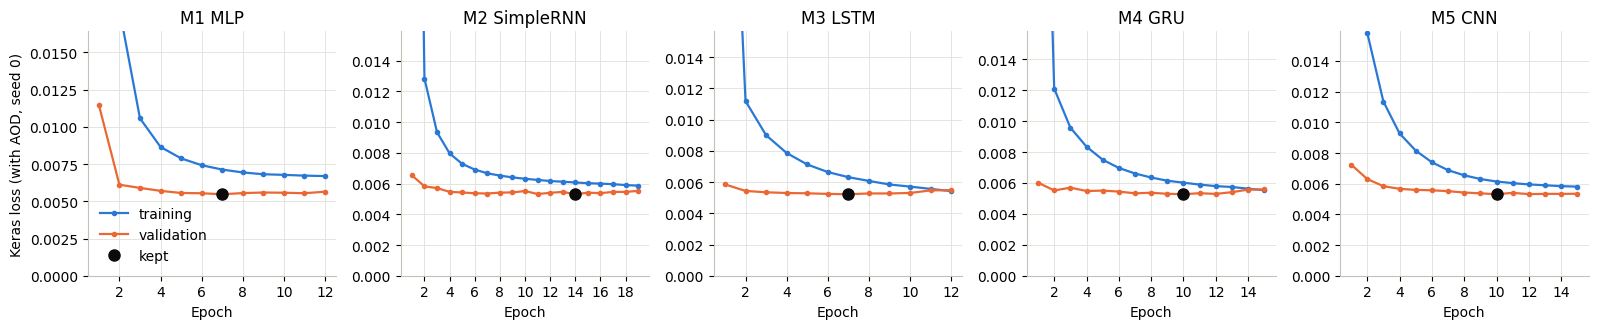

In [56]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, label in zip(axes, KERAS_MODELS):
    history = keras_runs[(label, 'with AOD', 0)]['history']
    best = history.loc[history['validation'].idxmin()]
    ax.plot(history['epoch'], history['train'], color='#2a78d6', marker='o', markersize=3, label='training')
    ax.plot(history['epoch'], history['validation'], color='#eb6834', marker='o', markersize=3, label='validation')
    ax.plot(best['epoch'], best['validation'], 'o', color='#0b0b0b', markersize=8, label='kept')
    ax.set(title=label, xlabel='Epoch', ylim=(0, 3 * best['validation']))
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_ylabel('Keras loss (with AOD, seed 0)')
axes[0].legend(loc='lower left')
fig.tight_layout()
save_figure(fig, 'fig10_keras_learning_curves')
plt.show()

In [57]:
all_runs = {}
for set_name, columns in INPUT_SETS.items():
    for seed in SEEDS:
        saved = np.load(f"{MODELS}/M0_{set_name.replace(' ', '_')}_seed{seed}.npz")
        net = {'W1': saved['W1'], 'b1': saved['b1'], 'W2': saved['W2'], 'b2': saved['b2'], 'hidden': 'tanh', 'output': 'linear'}
        all_runs[('M0 NumPy', set_name, seed)] = {'val': forward(make_inputs(VAL, columns), net)[1], 'test': saved['test_clearness']}
for key, run in keras_runs.items():
    all_runs[key] = {'val': run['val'], 'test': run['test']}

print('Trained networks with validation and test forecasts:', len(all_runs))

Trained networks with validation and test forecasts: 36


In [58]:
scores = []
for (model, set_name, seed), run in all_runs.items():
    val = evaluate(to_ghi(run['val'], VAL), VAL, use_target)
    test = evaluate(to_ghi(run['test'], TEST), TEST, is_day)
    for h in HORIZONS:
        scores.append({'model': model, 'inputs': set_name, 'seed': seed, 'horizon': h,
                       'val RMSE': val.loc[h, 'RMSE'], 'RMSE': test.loc[h, 'RMSE'], 'MAE': test.loc[h, 'MAE']})
scores = pd.DataFrame(scores)
scores.to_csv(f'{OUT}/all_network_scores.csv', index=False)

test_table = scores.pivot_table(index='model', columns=['inputs', 'horizon'], values='RMSE', aggfunc='mean', sort=False)
print('Best baseline RMSE on the test years:', best_baseline_rmse.round(1).to_dict())
print('Test RMSE (W/m2) of each network, mean over 3 random restarts:')
test_table.round(1)

Best baseline RMSE on the test years: {'t+1': 30.1, 't+6': 72.9, 't+24': 81.5}
Test RMSE (W/m2) of each network, mean over 3 random restarts:


inputs       with AOD             without AOD            
horizon           t+1   t+6  t+24         t+1   t+6  t+24
model                                                    
M0 NumPy         31.6  55.0  73.2        33.1  58.3  72.9
M1 MLP           33.6  55.2  71.7        33.9  58.5  71.9
M2 SimpleRNN     29.0  54.0  70.0        28.8  57.1  70.6
M3 LSTM          30.2  54.1  71.4        30.4  58.0  71.9
M4 GRU           28.8  53.9  71.2        29.5  55.9  71.7
M5 CNN           30.9  55.3  72.3        30.2  56.8  72.6

In [59]:
mean_scores = scores.groupby(['model', 'inputs', 'horizon'], sort=False)[['val RMSE', 'RMSE', 'MAE']].mean()
spread = scores.groupby(['model', 'inputs', 'horizon'], sort=False)['RMSE'].std()
BEST_NETWORK = mean_scores['val RMSE'].unstack('horizon').idxmin()          # chosen on validation, one per horizon

final = pd.DataFrame(index=HORIZONS)
final['network (chosen on validation)'] = [' / '.join(BEST_NETWORK[h]) for h in HORIZONS]
final['test RMSE'] = [mean_scores.loc[(*BEST_NETWORK[h], h), 'RMSE'] for h in HORIZONS]
final['test MAE'] = [mean_scores.loc[(*BEST_NETWORK[h], h), 'MAE'] for h in HORIZONS]
final['best baseline'] = [BEST_BASELINE[h] for h in HORIZONS]
final['baseline RMSE'] = best_baseline_rmse
final['better than baseline (%)'] = 100 * (1 - final['test RMSE'] / final['baseline RMSE'])
final.round(1)

,network (chosen on validation),test RMSE,test MAE,best baseline,baseline RMSE,better than baseline (%)
t+1,M4 GRU / with AOD,28.8,16.1,Smart persistence A,30.1,4.3
t+6,M0 NumPy / with AOD,55.0,29.6,Smart persistence B,72.9,24.5
t+24,M1 MLP / without AOD,71.9,39.5,Climatology,81.5,11.8


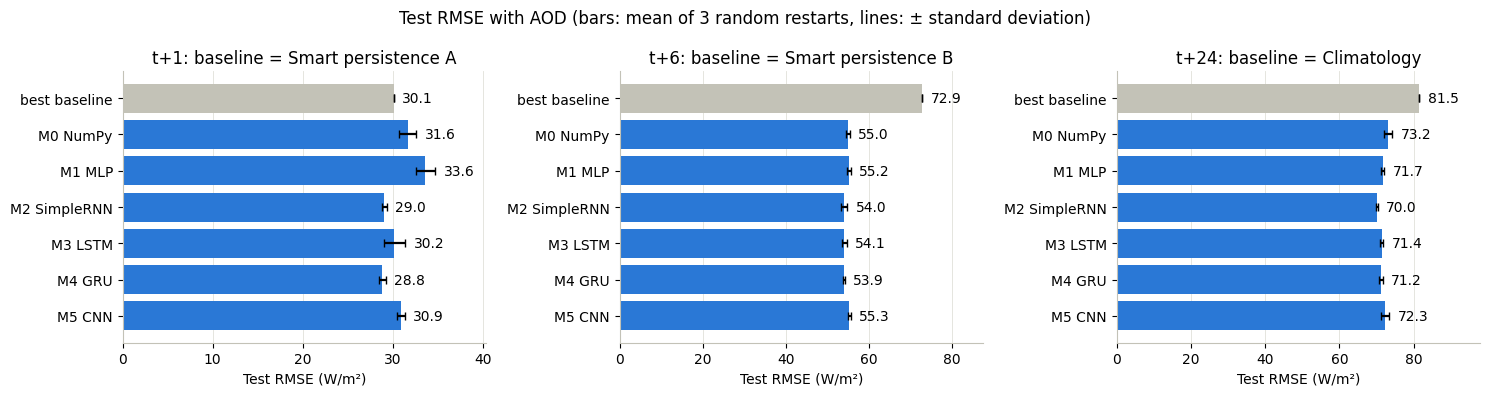

In [60]:
models = list(scores['model'].unique())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, h in zip(axes, HORIZONS):
    values = [best_baseline_rmse[h]] + [mean_scores.loc[(m, 'with AOD', h), 'RMSE'] for m in models]
    errors = [0] + [spread.loc[(m, 'with AOD', h)] for m in models]
    colours = ['#c3c2b7'] + ['#2a78d6'] * len(models)
    bars = ax.barh(['best baseline'] + models, values, xerr=errors, color=colours, capsize=3)
    ax.bar_label(bars, fmt='%.1f', padding=6)
    ax.invert_yaxis()
    ax.set(title=f'{h}: baseline = {BEST_BASELINE[h]}', xlabel='Test RMSE (W/m²)', xlim=(0, 1.2 * max(values)))
    ax.set_axisbelow(True)
    ax.grid(axis='y', visible=False)
fig.suptitle('Test RMSE with AOD (bars: mean of 3 random restarts, lines: ± standard deviation)')
fig.tight_layout()
save_figure(fig, 'fig11_networks_vs_baseline')
plt.show()

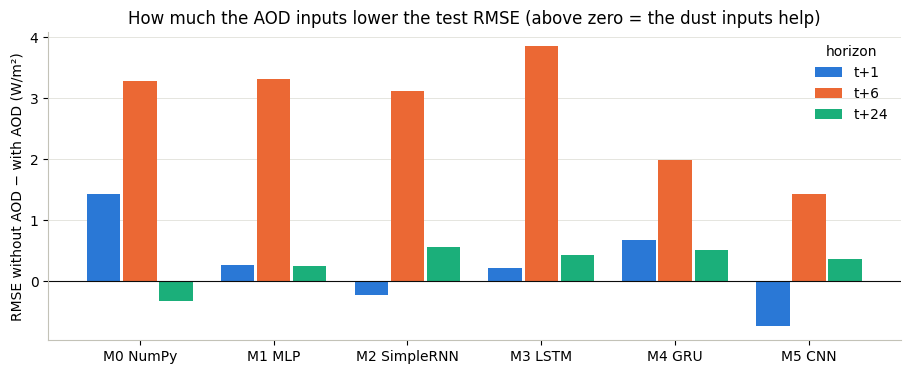

horizon,t+1,t+6,t+24
model,,,
M0 NumPy,1.4,3.3,-0.3
M1 MLP,0.3,3.3,0.2
M2 SimpleRNN,-0.2,3.1,0.6
M3 LSTM,0.2,3.9,0.4
M4 GRU,0.7,2.0,0.5
M5 CNN,-0.7,1.4,0.4


In [61]:
by_inputs = mean_scores['RMSE'].unstack('inputs')
aod_gain = (by_inputs['without AOD'] - by_inputs['with AOD']).unstack('horizon')[HORIZONS]     # positive = AOD helps

x = np.arange(len(aod_gain))
fig, ax = plt.subplots(figsize=(11, 4))
for i, (h, colour) in enumerate(zip(HORIZONS, ['#2a78d6', '#eb6834', '#1baf7a'])):
    ax.bar(x + (i - 1) * 0.27, aod_gain[h], width=0.25, color=colour, label=h)
ax.axhline(0, color='#0b0b0b', linewidth=0.8)
ax.set(title='How much the AOD inputs lower the test RMSE (above zero = the dust inputs help)',
       xticks=x, xticklabels=aod_gain.index, ylabel='RMSE without AOD − with AOD (W/m²)')
ax.set_axisbelow(True)
ax.grid(axis='x', visible=False)
ax.legend(title='horizon')
save_figure(fig, 'fig12_aod_effect')
plt.show()

aod_gain.round(1)

In [62]:
abu_dhabi = df[df['site'] == 'Abu Dhabi'].set_index('time')
daytime = abu_dhabi[(abu_dhabi['solar_zenith_deg'] < 85) & (abu_dhabi.index >= '2024-01-01')]
daily = daytime.groupby(daytime.index.date)[['aod_550nm', 'cloud_amount_pct']].mean()
clear_days = daily[daily['cloud_amount_pct'] < 20]

clean_day, dusty_day = clear_days['aod_550nm'].idxmin(), clear_days['aod_550nm'].idxmax()
print('Test days in Abu Dhabi with little cloud:', len(clear_days))
clear_days.loc[[clean_day, dusty_day]].round(2)

Test days in Abu Dhabi with little cloud: 119


,aod_550nm,cloud_amount_pct
2026-04-02,0.02,15.81
2025-04-08,0.67,17.35


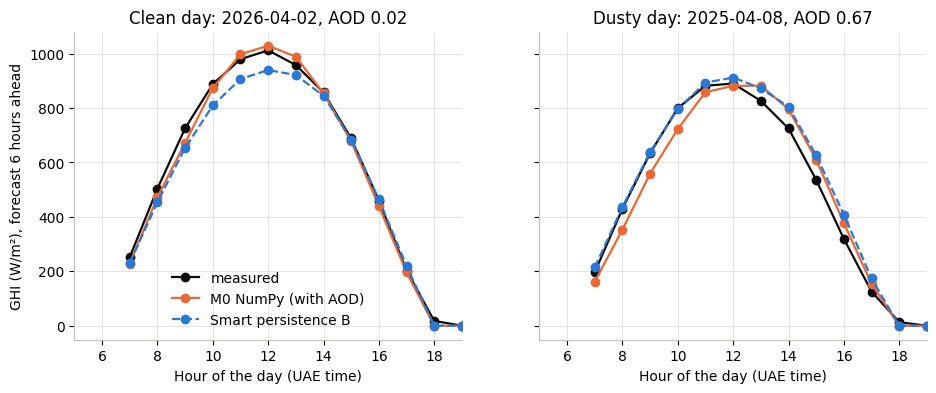

In [63]:
k = HORIZONS.index('t+6')
model_6, inputs_6 = BEST_NETWORK['t+6']
network_6 = to_ghi(all_runs[(model_6, inputs_6, 0)]['test'], TEST)
baseline_6 = BASELINES[BEST_BASELINE['t+6']]
site = df['site'].to_numpy()
dates = df['time'].dt.date.to_numpy()

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, day, name in zip(axes, [clean_day, dusty_day], ['Clean day', 'Dusty day']):
    rows = TEST[(site[target[TEST, k]] == 'Abu Dhabi') & (dates[target[TEST, k]] == day)]
    hour = pd.DatetimeIndex(times[target[rows, k]]).hour + 4                    # UAE time
    ax.plot(hour, ghi_target[rows, k], color='#0b0b0b', marker='o', label='measured')
    ax.plot(hour, network_6[rows, k], color='#eb6834', marker='o', label=f'{model_6} ({inputs_6})')
    ax.plot(hour, baseline_6[rows, k], color='#2a78d6', marker='o', linestyle='--', label=BEST_BASELINE['t+6'])
    ax.set(title=f'{name}: {day}, AOD {clear_days.loc[day, "aod_550nm"]:.2f}', xlabel='Hour of the day (UAE time)',
           xlim=(5, 19))
axes[0].set_ylabel('GHI (W/m²), forecast 6 hours ahead')
axes[0].legend(loc='lower center')
save_figure(fig, 'fig13_clean_and_dusty_test_day')
plt.show()

In [64]:
rows = TEST[is_day[TEST, k]]
target_rows = target[rows, k]
squared_errors = pd.DataFrame({'network': (network_6[rows, k] - ghi_target[rows, k]) ** 2,
                               'baseline': (baseline_6[rows, k] - ghi_target[rows, k]) ** 2}, dtype=float)
dust_level = pd.cut(df['aod_550nm'].to_numpy()[target_rows], bins=[0, 0.2, 0.4, 0.6, 0.8, 7],
                    labels=['0-0.2', '0.2-0.4', '0.4-0.6', '0.6-0.8', 'above 0.8'], include_lowest=True)

by_dust = squared_errors.groupby(dust_level, observed=True).mean() ** 0.5
by_dust['hours'] = dust_level.value_counts()
by_city = squared_errors.groupby(site[target_rows]).mean().loc[CITIES] ** 0.5
by_city['hours'] = pd.Series(site[target_rows]).value_counts()
print('t+6 test RMSE (W/m2) by dust level:')
print(by_dust.round(1))
print('\nt+6 test RMSE (W/m2) by city:')
print(by_city.round(1))

t+6 test RMSE (W/m2) by dust level:
           network  baseline  hours
0-0.2         38.5      69.0   2438
0.2-0.4       41.8      61.8   9691
0.4-0.6       53.0      70.1   9299
0.6-0.8       62.5      77.4   5789
above 0.8     73.2      92.2   4929

t+6 test RMSE (W/m2) by city:
           network  baseline  hours
Abu Dhabi     52.3      70.2  10708
Dubai         56.7      77.0  10709
Al Ain        54.6      71.4  10729


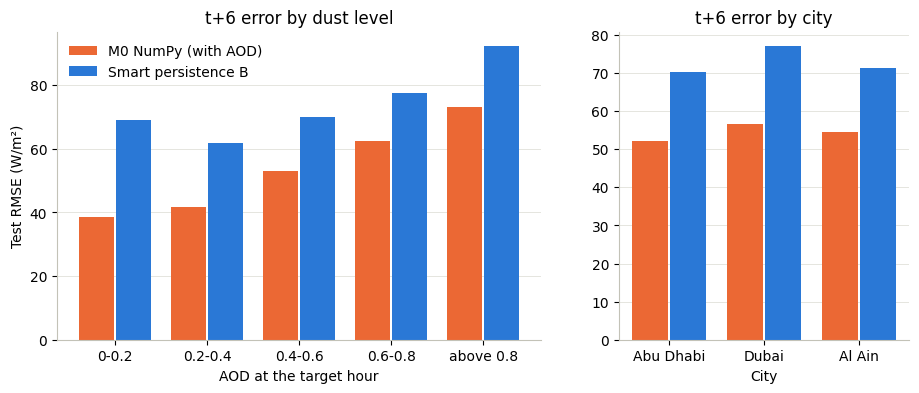

In [65]:
fig, (ax1, ax2) = plt.subplots(1, 2, gridspec_kw={'width_ratios': [5, 3]})
for ax, table, xlabel in [(ax1, by_dust, 'AOD at the target hour'), (ax2, by_city, 'City')]:
    x = np.arange(len(table))
    ax.bar(x - 0.2, table['network'], width=0.38, color='#eb6834', label=f'{model_6} ({inputs_6})')
    ax.bar(x + 0.2, table['baseline'], width=0.38, color='#2a78d6', label=BEST_BASELINE['t+6'])
    ax.set(xticks=x, xticklabels=table.index, xlabel=xlabel)
    ax.set_axisbelow(True)
    ax.grid(axis='x', visible=False)
ax1.set(title='t+6 error by dust level', ylabel='Test RMSE (W/m²)')
ax2.set(title='t+6 error by city')
ax1.legend(loc='upper left')
save_figure(fig, 'fig14_error_by_dust_and_city')
plt.show()

In [66]:
print('Figures saved in', FIGS)
for name in sorted(os.listdir(FIGS)):
    print('  ', name)

saved_networks = [name for name in os.listdir(MODELS) if name.endswith('.npz')]
print('\nTrained networks saved in', MODELS, ':', len(saved_networks))
print('Result tables saved in', OUT, ':', sorted(name for name in os.listdir(OUT) if name.endswith('.csv')))

Figures saved in /content/drive/MyDrive/MSc_AI_Project/outputs_v2/figures
   fig01_daily_and_seasonal_cycle.png
   fig02_dust_by_month_and_distribution.png
   fig03_clean_vs_dusty_day.png
   fig04_dust_physics_check.png
   fig05_train_validation_test_split.png
   fig06_one_training_sample.png
   fig07_baselines_test_rmse.png
   fig08_m0_learning_rate_search.png
   fig09_m0_learning_curves.png
   fig10_keras_learning_curves.png
   fig11_networks_vs_baseline.png
   fig12_aod_effect.png
   fig13_clean_and_dusty_test_day.png
   fig14_error_by_dust_and_city.png
   fig15_sky_class_confusion_matrix.png

Trained networks saved in /content/drive/MyDrive/MSc_AI_Project/outputs_v2/models : 36
Result tables saved in /content/drive/MyDrive/MSc_AI_Project/outputs_v2 : ['all_network_scores.csv', 'm0_learning_rate_search.csv']
